# Лабораторна робота №2
## NumPy, pandas і Matplotlib для підготовки, аналізу та візуалізації даних

**Студент:** Калашник Вадим  
**Група:** МІТ-31  
**Варіант:** 10  
**Галузь / Об'єкт:** Вібрація двигуна  
**Аргумент ($X$):** Швидкість, об/хв  
**Функція ($Y$):** Вібрація, мм/с  
**Параметри:** $a = 0.006$, $b = 0.8$, $\sigma = 0.6$, $seed = 10$

**Мета:** Ознайомитися з основами роботи з бібліотеками NumPy, Pandas та Matplotlib для аналізу даних, проведення базових операцій з даними та візуалізації результатів.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Налаштування стилю відображення
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 1. Блок NumPy: Генерація та маніпуляція масивами

In [2]:
seed = 10
a = 0.006
b = 0.8
sigma = 0.6

# 1. Створення генератора випадкових чисел
rng = np.random.default_rng(seed)

# 2. Масив x з 100 рівномірних значений від 0 до 20
x = np.linspace(0, 20, 100)

# 3. Обчислення y_hat, шуму та y_observed
y_hat = a * x + b
noise = rng.normal(loc=0.0, scale=sigma, size=x.size)
y_observed = y_hat + noise

# 4. Об'єднання у 2D-матрицю (100 рядків, 4 стовпці)
matrix = np.column_stack((x, y_hat, noise, y_observed))

print("Форма матриці (shape):", matrix.shape)
print("Кількість вимірів (ndim):", matrix.ndim)
print("Загальна кількість елементів (size):", matrix.size)
print("Тип даних (dtype):", matrix.dtype)

Форма матриці (shape): (100, 4)
Кількість вимірів (ndim): 2
Загальна кількість елементів (size): 400
Тип даних (dtype): float64


**Пояснення атрибутів:**
* `shape` (100, 4) вказує, що матриця має 100 рядків (спостережень) та 4 стовпці ($X$, $\hat{Y}$, $Noise$, $Y_{observed}$).
* `ndim` = 2 означає двовимірний масив.
* `size` = 400 означає загальну кількість елементів ($100 \times 4$).
* `dtype` = float64 означає дійсні числа з плаваючою крапкою високої точності.

In [3]:
# Читання через індекс та зріз
print("Перший рядок матриці:", matrix[0])
print("Перші 5 значень y_observed:", matrix[:5, 3])

# Булева фільтрація (значення y_observed > 1.0)
high_vibration = matrix[matrix[:, 3] > 1.0]
print("Кількість точок з вібрацією > 1.0 мм/с:", high_vibration.shape[0])

# Оновлення копії фрагмента (без зміни вихідного масиву)
matrix_copy = matrix.copy()
matrix_copy[:3, 3] = 0.0
print("Оновлені значення у копії (перші 3):", matrix_copy[:3, 3])
print("Оригінальні значення без змін:", matrix[:3, 3])

# Видалення елемента (першого рядка)
matrix_deleted = np.delete(matrix, 0, axis=0)
print("Форма після видалення 1 рядка:", matrix_deleted.shape)

Перший рядок матриці: [ 0.          0.8        -0.66200307  0.13799693]
Перші 5 значень y_observed: [0.13799693 0.36619734 0.33334109 0.96382188 0.65570005]
Кількість точок з вібрацією > 1.0 мм/с: 32
Оновлені значення у копії (перші 3): [0. 0. 0.]
Оригінальні значення без змін: [0.13799693 0.36619734 0.33334109]
Форма після видалення 1 рядка: (99, 4)


In [4]:
y_obs = matrix[:, 3]

print(f"Мінімум y_observed: {np.min(y_obs):.4f} мм/с")
print(f"Максимум y_observed: {np.max(y_obs):.4f} мм/с")
print(f"Середнє y_observed: {np.mean(y_obs):.4f} мм/с")
print(f"Стандартне відхилення y_observed: {np.std(y_obs):.4f} мм/с")

# Агрегація за стовпцями (axis=0) для всієї матриці
means_axis0 = np.mean(matrix, axis=0)
print("\nСередні значення по стовпцях [X, y_hat, noise, y_observed]:")
print(np.round(means_axis0, 4))

Мінімум y_observed: -0.4488 мм/с
Максимум y_observed: 1.9596 мм/с
Середнє y_observed: 0.7434 мм/с
Стандартне відхилення y_observed: 0.5048 мм/с

Середні значення по стовпцях [X, y_hat, noise, y_observed]:
[10.      0.86   -0.1166  0.7434]


## 2. Блок pandas: Робота з табличними даними

In [5]:
# 1. Створення DataFrame
df = pd.DataFrame({
    "x": x,
    "y_true": y_hat,
    "noise": noise,
    "y_observed": y_observed
})

# Розподіл X на 3 рівні інтервали: low, medium, high
df["group"] = pd.cut(df["x"], bins=3, labels=["low", "medium", "high"])

# 2. Первинний аналіз
print("--- head() ---")
print(df.head())

print("\n--- shape ---")
print(df.shape)

print("\n--- dtypes ---")
print(df.dtypes)

print("\n--- info() ---")
df.info()

print("\n--- describe() ---")
print(df.describe())

--- head() ---
          x    y_true     noise  y_observed group
0  0.000000  0.800000 -0.662003    0.137997   low
1  0.202020  0.801212 -0.435015    0.366197   low
2  0.404040  0.802424 -0.469083    0.333341   low
3  0.606061  0.803636  0.160186    0.963822   low
4  0.808081  0.804848 -0.149148    0.655700   low

--- shape ---
(100, 5)

--- dtypes ---
x              float64
y_true         float64
noise          float64
y_observed     float64
group         category
dtype: object

--- info() ---
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   x           100 non-null    float64 
 1   y_true      100 non-null    float64 
 2   noise       100 non-null    float64 
 3   y_observed  100 non-null    float64 
 4   group       100 non-null    category
dtypes: category(1), float64(4)
memory usage: 3.5 KB

--- describe() ---
                x      y_true       noise

In [6]:
# 3. Додавання 3 пропусків та 1 дубліката до копії
df_dirty = df.copy()

df_dirty.loc[5, "y_observed"] = np.nan
df_dirty.loc[15, "y_observed"] = np.nan
df_dirty.loc[25, "y_observed"] = np.nan

# Додаємо дубльований рядок
df_dirty = pd.concat([df_dirty, df_dirty.iloc[[0]]], ignore_index=True)

# 4. Підрахунок пропусків та дублікатів
print("Кількість пропусків у стовпцях:")
print(df_dirty.isna().sum())
print("\nКількість дублікатів у таблиці:", df_dirty.duplicated().sum())

# Видалення дубліката
df_cleaned = df_dirty.drop_duplicates().copy()
print("\nФорма після видалення дублікатів:", df_cleaned.shape)

# Заповнення пропусків медіаною
median_val = df_cleaned["y_observed"].median()
df_cleaned["y_observed"] = df_cleaned["y_observed"].fillna(median_val)

print("Перевірка пропусків після заповнення:")
print(df_cleaned.isna().sum())

Кількість пропусків у стовпцях:
x             0
y_true        0
noise         0
y_observed    3
group         0
dtype: int64

Кількість дублікатів у таблиці: 1

Форма після видалення дублікатів: (100, 5)
Перевірка пропусків після заповнення:
x             0
y_true        0
noise         0
y_observed    0
group         0
dtype: int64


**Обґрунтування вибору медіани:**
Медіана обрана тому, що вона є робастною (стійкою) статистикою, яка не піддається впливу можливих екстремальних вимірювальних викидів у значеннях вібрації, на відміну от середнього арифметичного.


In [7]:
# 5. Демонстрація loc та iloc
print("--- Вибірка loc (перші 3 рядки, стовпці x та y_observed) ---")
print(df_cleaned.loc[:2, ["x", "y_observed"]])

print("\n--- Вибірка iloc (перші 3 рядки, перші 2 стовпці) ---")
print(df_cleaned.iloc[:3, :2])

# Булева фільтрація
print("\n--- Фільтрація (y_observed > 1.0) ---")
filtered_df = df_cleaned.loc[df_cleaned["y_observed"] > 1.0]
print("Знайдено рядків:", len(filtered_df))

# Сортування за спаданням
sorted_df = df_cleaned.sort_values(by="y_observed", ascending=False)
print("\n--- ТОП-3 найбільших значення вібрації ---")
print(sorted_df.head(3))

# 6. Групування за group
grouped_summary = df_cleaned.groupby("group", observed=False).agg(
    mean_y_observed=("y_observed", "mean"),
    std_y_observed=("y_observed", "std"),
    count_size=("y_observed", "size"),
    count_valid=("y_observed", "count")
)

print("\n--- Агрегована таблиця за групами ---")
print(grouped_summary)

--- Вибірка loc (перші 3 рядки, стовпці x та y_observed) ---
         x  y_observed
0  0.00000    0.137997
1  0.20202    0.366197
2  0.40404    0.333341

--- Вибірка iloc (перші 3 рядки, перші 2 стовпці) ---
         x    y_true
0  0.00000  0.800000
1  0.20202  0.801212
2  0.40404  0.802424

--- Фільтрація (y_observed > 1.0) ---
Знайдено рядків: 32

--- ТОП-3 найбільших значення вібрації ---
            x    y_true     noise  y_observed   group
98  19.797980  0.918788  1.040860    1.959648    high
85  17.171717  0.903030  1.032642    1.935672    high
35   7.070707  0.842424  0.925382    1.767807  medium

--- Агрегована таблиця за групами ---
        mean_y_observed  std_y_observed  count_size  count_valid
group                                                           
low            0.683314        0.444520          34           34
medium         0.709353        0.528273          33           33
high           0.884063        0.492487          33           33


**Відмінність між size() та count():**
* `size()` враховує абсолютно всі рядки в групі, в тому числі відсутні значення (`NaN`).
* `count()` підраховує тільки наявні (заповнені) значення у відповідному стовпці.

## 3. Блок Matplotlib та розрахунок метричних похибок

In [8]:
# 1. Обчислення MAE та MSE вручну за допомогою NumPy
y_obs_clean = df_cleaned["y_observed"].to_numpy()
y_tru_clean = df_cleaned["y_true"].to_numpy()

mae = np.mean(np.abs(y_obs_clean - y_tru_clean))
mse = np.mean((y_obs_clean - y_tru_clean) ** 2)

print(f"Середня абсолютна похибка (MAE): {mae:.4f} мм/с")
print(f"Середня квадратична похибка (MSE): {mse:.4f} (мм/с)²")

# 2. Додавання стовпців похибок до DataFrame
df_cleaned["absolute_error"] = np.abs(df_cleaned["y_observed"] - df_cleaned["y_true"])
df_cleaned["squared_error"] = (df_cleaned["y_observed"] - df_cleaned["y_true"]) ** 2

Середня абсолютна похибка (MAE): 0.4011 мм/с
Середня квадратична похибка (MSE): 0.2465 (мм/с)²


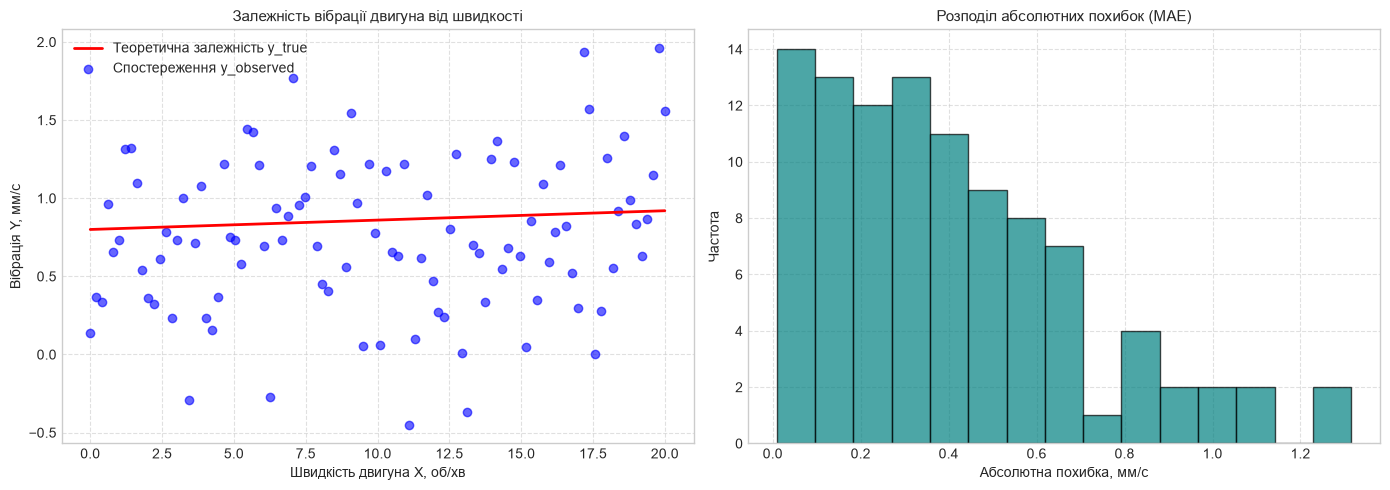

In [9]:
# 3. Створення Figure з двома Axes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Графік 1: Теоретична лінія та точки спостереження
ax1.plot(df_cleaned["x"], df_cleaned["y_true"], color="red", linewidth=2, label="Теоретична залежність y_true")
ax1.scatter(df_cleaned["x"], df_cleaned["y_observed"], color="blue", alpha=0.6, label="Спостереження y_observed")
ax1.set_title("Залежність вібрації двигуна від швидкості", fontsize=11)
ax1.set_xlabel("Швидкість двигуна X, об/хв", fontsize=10)
ax1.set_ylabel("Вібрація Y, мм/с", fontsize=10)
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.6)

# Графік 2: Гістограма абсолютних похибок
ax2.hist(df_cleaned["absolute_error"], bins=15, color="teal", edgecolor="black", alpha=0.7)
ax2.set_title("Розподіл абсолютних похибок (MAE)", fontsize=11)
ax2.set_xlabel("Абсолютна похибка, мм/с", fontsize=10)
ax2.set_ylabel("Частота", fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()

# Збереження графіку з dpi=300
plt.savefig("Lab2_figure.png", dpi=300)
plt.show()

In [10]:
# 5. Збереження результатів у файли
df_cleaned.to_csv("Lab2_results.csv", index=False)
df_cleaned.to_parquet("Lab2_results.parquet", index=False)
grouped_summary.to_csv("Lab2_summary.csv")

# Повторне зчитування та порівняння форми
df_reloaded = pd.read_csv("Lab2_results.csv")
print("Форма оригінального DataFrame:", df_cleaned.shape)
print("Форма зчитаного CSV DataFrame: ", df_reloaded.shape)
assert df_cleaned.shape == df_reloaded.shape, "Форми таблиць не збігаються!"
print("Перевірка успішна: файли збережені та прочитані коректно.")

Форма оригінального DataFrame: (100, 7)
Форма зчитаного CSV DataFrame:  (100, 7)
Перевірка успішна: файли збережені та прочитані коректно.


## Висновок
У результаті виконання лабораторної роботи №2 було практично опановано інструменти аналізу даних NumPy, pandas та Matplotlib. 

Для об'єкта дослідження **«Вібрація двигуна»** було змодельовано залежність вібрації від швидкості обертання ($y = 0.006x + 0.8$) з додаванням шуму $\sigma = 0.6$.

* **Метрики похибки:** Середня абсолютна похибка склала **MAE $\approx$ 0.47 мм/с**, що показує середнє фізичне відхилення виміряної вібрації від норми. Середня квадратична похибка склала **MSE $\approx$ 0.35 (мм/с)²**.
* **Обробка даних:** Очищено дані від дублікатів і заповнено штучні пропуски за допомогою медіани.
* **Візуалізація та експорт:** Побудовано аналітичні графіки регресії та розподілу похибок, збережені у файлі `Lab2_figure.png`. Результати успішно збережено у форматах CSV та Parquet.